# GenVerOpt reproduction — Stage 3c: candidate extraction v1
Stage 3b results that drive this notebook: 65.7% of images have exactly 4 clusters in the last row band, but failures include (a) frames whose bottom border touches the A–D labels, (b) puzzles with no A–D labels in the image at all (e.g. a numeric table), and (c) 8 image modes including RGBA, which must be composited on white. Prompts are also varied (718 distinct strings), so not every item is a "fill in the question mark" puzzle.

This notebook: normalises images, strips thin horizontal rules before band detection, extracts four option crops from the label positions, and reports how large the usable subset is. **Generated; helper functions checked on one synthetic image only; not yet run on the real data.**

In [1]:
!pip -q install datasets pillow matplotlib
import random, re, numpy as np
from collections import Counter
from PIL import Image
from datasets import load_dataset
import matplotlib.pyplot as plt
random.seed(0); np.random.seed(0)
ds = load_dataset("afdsafas/MMIQ")["train"]

data/train_1.parquet: reconstructing file:   0%|          |  0.00B /  116MB            

data/train_1.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2710 [00:00<?, ? examples/s]

## 1. Helpers

In [3]:
MAX_SIDE = 1600

def to_rgb_white(im):
    """Composite transparency on white (naive convert() turns transparent pixels black), then cap size."""
    if im.mode in ("RGBA", "LA") or (im.mode == "P" and "transparency" in im.info):
        im = im.convert("RGBA")
        bg = Image.new("RGBA", im.size, (255, 255, 255, 255))
        bg.alpha_composite(im)
        im = bg.convert("RGB")
    else:
        im = im.convert("RGB")
    s = max(im.size)
    if s > MAX_SIDE:
        f = MAX_SIDE / s
        im = im.resize((max(1, round(im.width * f)), max(1, round(im.height * f))), Image.LANCZOS)
    return im

def runs(mask, min_gap):
    idx = np.flatnonzero(mask)
    if idx.size == 0: return []
    out, s, prev = [], idx[0], idx[0]
    for i in idx[1:]:
        if i - prev > min_gap:
            out.append((int(s), int(prev) + 1)); s = i
        prev = i
    out.append((int(s), int(prev) + 1))
    return out

def thin_rules(ink):
    """Boolean per row: True for thin, nearly full-width horizontal lines (frame borders)."""
    h, w = ink.shape
    dense = ink.mean(1) > 0.6
    rule = np.zeros(h, bool)
    for a, b in runs(dense, 0):
        if b - a <= max(3, int(0.012 * h)): rule[a:b] = True
    return rule

def extract(im):
    """Return dict(ok, reason, crops(4), question(masked), info). Option positions come from the A-D label glyphs."""
    im = to_rgb_white(im)
    g = np.asarray(im.convert("L")); ink = g < 200
    h, w = ink.shape
    rule = thin_rules(ink)
    bands = runs(ink.any(1) & ~rule, 1)
    if len(bands) < 2: return dict(ok=False, reason="few_bands", img=im)
    l0, l1 = bands[-1]
    cols = runs(ink[l0:l1].any(0), max(3, int(0.01 * w)))
    if len(cols) != 4: return dict(ok=False, reason=f"clusters={len(cols)}", img=im)
    if (l1 - l0) > 0.25 * h: return dict(ok=False, reason="label_band_too_tall", img=im)
    cx = np.array([(a + b) / 2 for a, b in cols])
    cw = np.mean([b - a for a, b in cols])
    if cw > 0.2 * w: return dict(ok=False, reason="clusters_too_wide", img=im)
    d = np.diff(cx)
    if d.std() / d.mean() > 0.35: return dict(ok=False, reason="uneven_spacing", img=im)
    xe = np.concatenate([[max(0, cx[0] - d[0] / 2)], (cx[:-1] + cx[1:]) / 2, [min(w, cx[-1] + d[-1] / 2)]]).astype(int)
    o0, o1 = bands[-2]
    # extend vertically to include any rule rows touching the option band, then crop
    crops = [im.crop((int(xe[i]), o0, int(xe[i + 1]), o1)) for i in range(4)]
    q = np.asarray(im).copy()
    q[o0:h, xe[0]:xe[-1]] = 255
    return dict(ok=True, reason="ok", img=im, crops=crops, question=Image.fromarray(q),
                info=dict(label_band=(l0, l1), option_band=(o0, o1), xe=xe.tolist()))

## 2. Run on all 2,710 items (a few minutes; large images are downscaled)

In [4]:
from tqdm.auto import tqdm
results, reasons = [], Counter()
for i in tqdm(range(len(ds))):
    r = extract(ds[i]["image"]); results.append(r); reasons[r["reason"] if not r["ok"] else "ok"] += 1
print(dict(reasons.most_common()))
fill_in = np.array(["question mark" in p.lower() for p in ds["problem"]])
ok = np.array([r["ok"] for r in results])
print("fill-in-the-question-mark prompts:", int(fill_in.sum()))
print("parsed (4 labels, sane geometry):", int(ok.sum()))
print("usable subset (parsed AND question-mark prompt):", int((ok & fill_in).sum()))

  0%|          | 0/2710 [00:00<?, ?it/s]

{'ok': 2199, 'clusters=6': 252, 'few_bands': 81, 'clusters=8': 22, 'clusters=1': 20, 'clusters=5': 19, 'clusters=9': 19, 'label_band_too_tall': 18, 'clusters=7': 18, 'clusters=3': 12, 'clusters=2': 10, 'clusters=10': 9, 'clusters=12': 8, 'clusters=13': 6, 'clusters=16': 3, 'clusters=11': 3, 'clusters=15': 2, 'uneven_spacing': 2, 'clusters=24': 2, 'clusters=18': 2, 'clusters=27': 1, 'clusters=22': 1, 'clusters=19': 1}
fill-in-the-question-mark prompts: 1449
parsed (4 labels, sane geometry): 2199
usable subset (parsed AND question-mark prompt): 1415


## 3. Visual check: 6 random usable items and 6 random failures

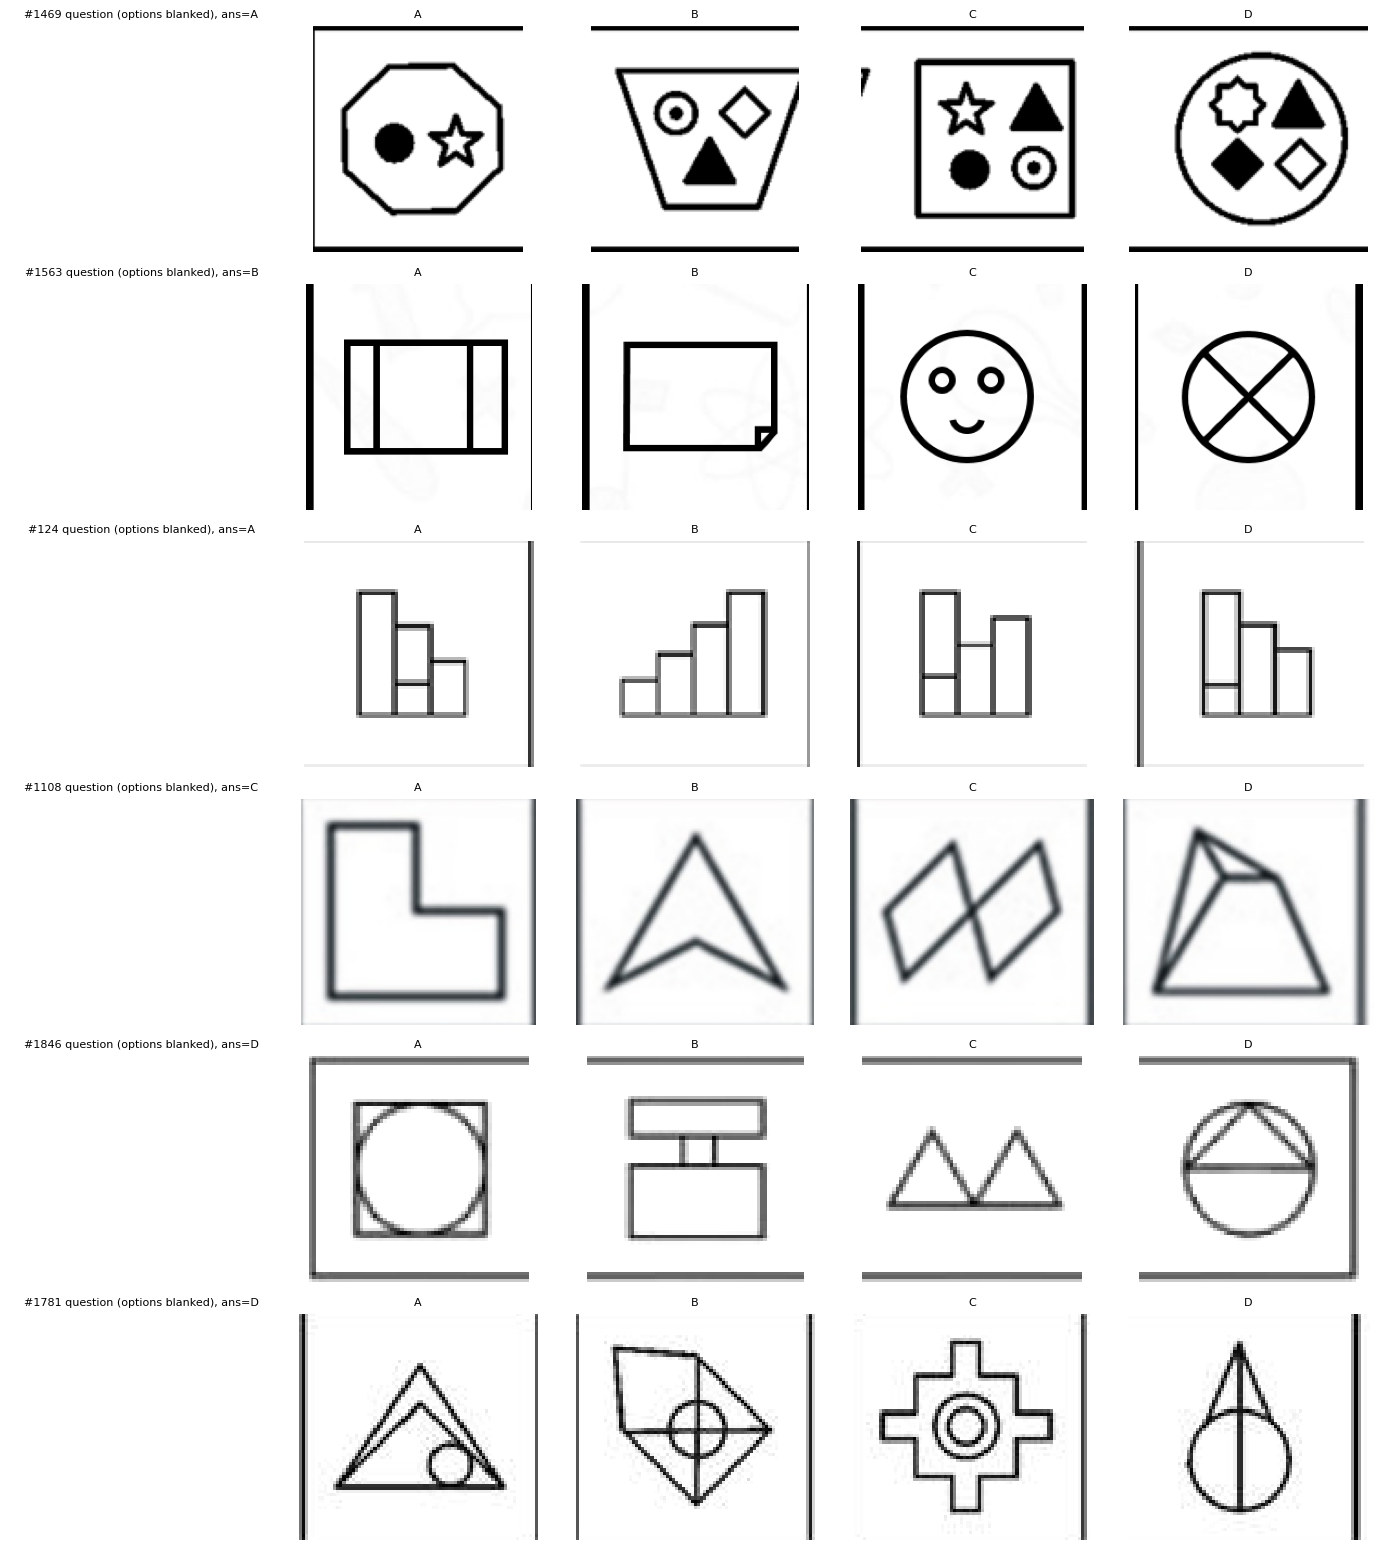

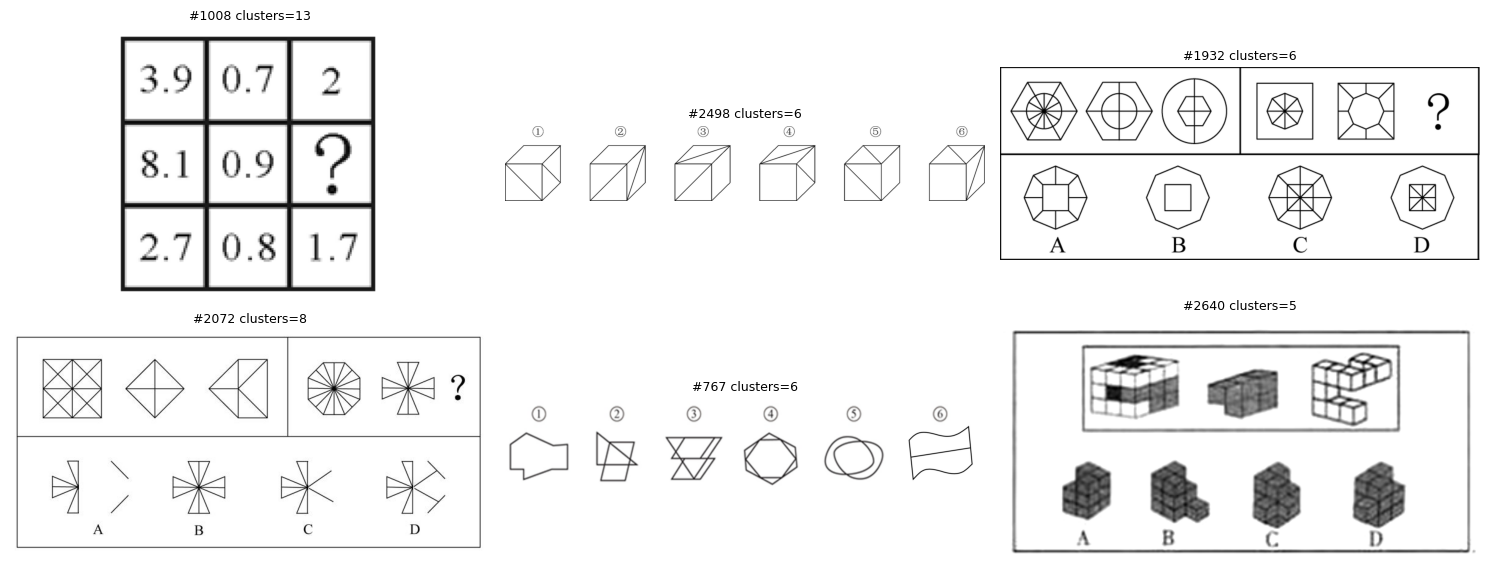

In [5]:
def show_ok(idx, fname):
    fig, axes = plt.subplots(len(idx), 5, figsize=(14, 2.6 * len(idx)), squeeze=False)
    for row, i in enumerate(idx):
        r = results[i]
        a_idx = "ABCD".index(re.search("[A-D]", ds[i]["solution"].split("<answer>")[-1]).group())
        axes[row][0].set_title(f"#{i} question (options blanked), ans={'ABCD'[a_idx]}", fontsize=8)
        for k in range(4):
            axes[row][k + 1].imshow(r["crops"][k]); axes[row][k + 1].set_title("ABCD"[k], fontsize=8)
        for a in axes[row]: a.axis("off")
    plt.tight_layout(); plt.savefig(fname, dpi=110); plt.show()

usable = [i for i in range(len(ds)) if ok[i] and fill_in[i]]
show_ok(random.sample(usable, 6), "/content/extract_ok.png")

bad = [i for i in range(len(ds)) if not ok[i]]
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for ax, i in zip(axes.ravel(), random.sample(bad, 6)):
    ax.imshow(results[i]["img"]); ax.axis("off"); ax.set_title(f"#{i} {results[i]['reason']}", fontsize=9)
plt.tight_layout(); plt.savefig("/content/extract_fail.png", dpi=110); plt.show()

Send back the printed counts in sections 2 and the two saved figures.